In [3]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    "mysql+pymysql",
    username="ds_portfolio",
    password=getpass("MySQL password: "),
    host="127.0.0.1",
    port=3306,
    database="ecommerce_repurchase"
)

engine = create_engine(url)

In [4]:

query = "SELECT * FROM customer_snapshots_candidate"

df = pd.read_sql(
    query,
    con=engine,
    parse_dates=["cutoff_date"]
)

print(df.shape)
display(df.head())
print(df.dtypes)

(17957, 6)


,cutoff_date,customer_id,recency_days,frequency_6m,monetary_6m,repurchase
0,2010-06-01,13085,123,6,2017.20,0
1,2010-06-01,13078,5,14,7269.96,1
2,2010-06-01,15362,182,1,310.75,0
3,2010-06-01,18102,11,45,154566.35,1
4,2010-06-01,12682,26,10,5751.50,1


cutoff_date     datetime64[ns]
customer_id              int64
recency_days             int64
frequency_6m             int64
monetary_6m            float64
repurchase               int64
dtype: object


In [5]:

# 1. Check missing values
print("Missing values:")
print(df.isna().sum())

# 2. Check duplicate customer-cutoff combinations
duplicate_count = df.duplicated(
    subset=["cutoff_date", "customer_id"]
).sum()

print("\nDuplicate samples:", duplicate_count)

# 3. Check target distribution
print("\nTarget distribution:")
print(df["repurchase"].value_counts())


Missing values:
cutoff_date     0
customer_id     0
recency_days    0
frequency_6m    0
monetary_6m     0
repurchase      0
dtype: int64

Duplicate samples: 0

Target distribution:
repurchase
0    9035
1    8922
Name: count, dtype: int64


In [6]:
train_df = df[df["cutoff_date"] < "2011-06-01"].copy()

val_df = df[df["cutoff_date"] == "2011-06-01"].copy()

test_df = df[df["cutoff_date"] == "2011-09-01"].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Train: (12426, 6)
Validation: (2718, 6)
Test: (2813, 6)


In [7]:

feature_cols = [
    "recency_days",
    "frequency_6m",
    "monetary_6m"
]

target_col = "repurchase"

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)


X_train: (12426, 3)
y_train: (12426,)


In [8]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Build a preprocessing + modeling pipeline
baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Fit on training data only
baseline.fit(X_train, y_train)

# Predicted probability of repurchase = 1
val_proba = baseline.predict_proba(X_val)[:, 1]

# Evaluate on validation data
val_auc = roc_auc_score(y_val, val_proba)

print(f"Validation ROC-AUC: {val_auc:.4f}")


Validation ROC-AUC: 0.7414


In [9]:
import pandas as pd
import numpy as np

# 1. 从 Pipeline 中提取训练好的 Logistic Regression
lr_model = baseline.named_steps["logisticregression"]

# 2. 获取每个特征对应的系数
coef_df = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": lr_model.coef_[0]
})

# 3. 计算 Odds Ratio
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])

# 4. 按系数从大到小排序
coef_df = coef_df.sort_values(
    by="coefficient",
    ascending=False
)

coef_df

,feature,coefficient,odds_ratio
1,frequency_6m,1.646953,5.191140
2,monetary_6m,0.166671,1.181366
0,recency_days,-0.201422,0.817567


In [10]:
X_train[
    ["frequency_6m", "monetary_6m", "recency_days"]
].corr()

,frequency_6m,monetary_6m,recency_days
frequency_6m,1.000000,0.634419,-0.299783
monetary_6m,0.634419,1.000000,-0.154454
recency_days,-0.299783,-0.154454,1.000000


In [11]:
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. 计算 Validation Set 的正样本比例
positive_rate = y_val.mean()

# 2. 获取模型预测的复购概率
y_val_proba = baseline.predict_proba(X_val)[:, 1]

# 3. 计算评价指标
roc_auc = roc_auc_score(y_val, y_val_proba)
avg_precision = average_precision_score(y_val, y_val_proba)

print(f"Validation positive rate: {positive_rate:.4f}")
print(f"Validation ROC-AUC: {roc_auc:.4f}")
print(f"Validation Average Precision: {avg_precision:.4f}")

Validation positive rate: 0.4963
Validation ROC-AUC: 0.7414
Validation Average Precision: 0.7641


In [12]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# 1. 使用默认阈值 0.5 预测类别
y_val_pred = baseline.predict(X_val)

# 2. 计算 Confusion Matrix
cm = confusion_matrix(y_val, y_val_pred)

# 3. 提取四种分类结果
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print(f"\nTN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

# 4. 计算评价指标
print(f"\nAccuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_val_pred):.4f}")

Confusion Matrix:
[[1207  162]
 [ 715  634]]

TN: 1207
FP: 162
FN: 715
TP: 634

Accuracy:  0.6773
Precision: 0.7965
Recall:    0.4700
F1-Score:  0.5911


In [13]:
# Threshold = 0.3
threshold = 0.3

# 将预测概率转换成预测类别
y_pred_03 = (y_val_proba >= threshold).astype(int)

# 计算 Confusion Matrix
cm_03 = confusion_matrix(y_val, y_pred_03)

tn, fp, fn, tp = cm_03.ravel()

print(f"TN: {tn}, FP: {fp}")
print(f"FN: {fn}, TP: {tp}")

print(f"Precision: {precision_score(y_val, y_pred_03):.4f}")
print(f"Recall: {recall_score(y_val, y_pred_03):.4f}")
print(f"F1-Score: {f1_score(y_val, y_pred_03):.4f}")

TN: 325, FP: 1044
FN: 126, TP: 1223
Precision: 0.5395
Recall: 0.9066
F1-Score: 0.6764


In [14]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "predicted_positive": y_pred.sum(),
        "precision": precision_score(y_val, y_pred, zero_division=0),
        "recall": recall_score(y_val, y_pred, zero_division=0),
        "f1": f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

threshold_df

,threshold,predicted_positive,precision,recall,f1
0,0.3,2267,0.539479,0.906597,0.676438
1,0.4,1296,0.699846,0.672350,0.685822
2,0.5,796,0.796482,0.469978,0.591142
3,0.6,524,0.854962,0.332098,0.478377
4,0.7,367,0.907357,0.246850,0.388112


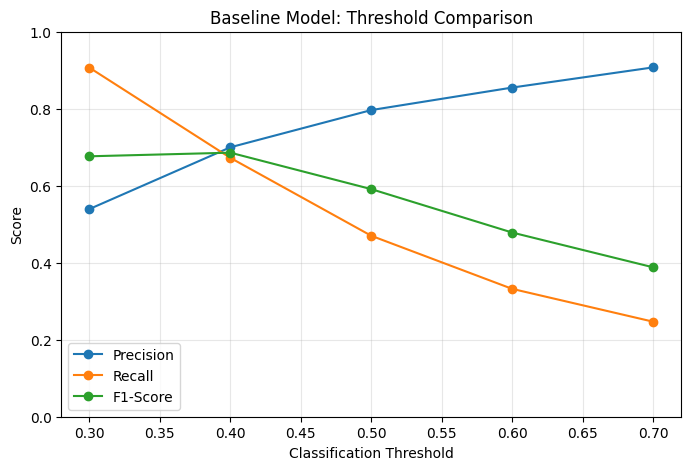

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Baseline Model: Threshold Comparison")

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [16]:
rfm_cols = [
    "recency_days",
    "frequency_6m",
    "monetary_6m"
]

# 查看分位数和描述性统计
X_train[rfm_cols].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).T


,count,mean,std,min,50%,90%,95%,99%,max
recency_days,12426.0,65.648479,51.458648,1.0,52.000,145.00,166.000,180.0000,184.00
frequency_6m,12426.0,2.947127,4.566577,1.0,2.000,6.00,8.000,19.0000,126.00
monetary_6m,12426.0,1358.357882,4993.140253,1.3,543.585,2399.64,3900.125,13896.2625,166763.39


In [17]:
# 查看偏度（Skewness）
X_train[rfm_cols].skew()

recency_days     0.595202
frequency_6m     9.360807
monetary_6m     19.074898
dtype: float64

In [18]:
import numpy as np
import pandas as pd

# 1. 复制训练数据，保留原始 X_train
X_train_log = X_train.copy()

# 2. 对两个右偏特征进行 Log Transformation
log_cols = ["frequency_6m", "monetary_6m"]

for col in log_cols:
    X_train_log[col] = np.log1p(X_train_log[col])

# 3. 比较变换前后的 Skewness
skew_comparison = pd.DataFrame({
    "original": X_train[rfm_cols].skew(),
    "log_transformed": X_train_log[rfm_cols].skew()
})

skew_comparison

,original,log_transformed
recency_days,0.595202,0.595202
frequency_6m,9.360807,1.536040
monetary_6m,19.074898,0.299762


In [19]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. 对 Validation Set 进行相同的 Log Transformation
X_val_log = X_val.copy()

for col in log_cols:
    X_val_log[col] = np.log1p(X_val_log[col])

# 2. 复制原始 Baseline 的模型配置
log_baseline = clone(baseline)

# 3. 使用变换后的训练数据拟合模型
log_baseline.fit(X_train_log, y_train)

# 4. 计算 Validation Set 的预测概率
y_val_log_proba = log_baseline.predict_proba(X_val_log)[:, 1]

# 5. 模型评估
log_roc_auc = roc_auc_score(y_val, y_val_log_proba)
log_ap = average_precision_score(y_val, y_val_log_proba)

print(f"Original ROC-AUC: 0.7414")
print(f"Log ROC-AUC:      {log_roc_auc:.4f}")
print(f"Log Average Precision: {log_ap:.4f}")

Original ROC-AUC: 0.7414
Log ROC-AUC:      0.7535
Log Average Precision: 0.7739


In [20]:
coef_comparison = pd.DataFrame({
    "feature": feature_cols,
    "original_coef": baseline.named_steps[
        "logisticregression"
    ].coef_[0],
    "log_coef": log_baseline.named_steps[
        "logisticregression"
    ].coef_[0]
})

coef_comparison

,feature,original_coef,log_coef
0,recency_days,-0.201422,-0.139562
1,frequency_6m,1.646953,0.694815
2,monetary_6m,0.166671,0.307744


In [21]:
# Correlation before Log Transformation
corr_original = X_train[rfm_cols].corr()

# Correlation after Log Transformation
corr_log = X_train_log[rfm_cols].corr()

print("Original Correlation:")
display(corr_original.round(3))

print("Log-transformed Correlation:")
display(corr_log.round(3))

Original Correlation:


,recency_days,frequency_6m,monetary_6m
recency_days,1.000,-0.300,-0.154
frequency_6m,-0.300,1.000,0.634
monetary_6m,-0.154,0.634,1.000


Log-transformed Correlation:


,recency_days,frequency_6m,monetary_6m
recency_days,1.00,-0.470,-0.400
frequency_6m,-0.47,1.000,0.753
monetary_6m,-0.40,0.753,1.000


In [22]:
# 保留之前的 Log-transformed Baseline
X_train_fe = X_train_log.copy()
X_val_fe = X_val_log.copy()

# 新增最近30天是否活跃的特征
X_train_fe["active_last_30d"] = (
    X_train_fe["recency_days"] <= 30
).astype(int)

X_val_fe["active_last_30d"] = (
    X_val_fe["recency_days"] <= 30
).astype(int)

# 检查训练集中的活跃客户占比
X_train_fe["active_last_30d"].value_counts(normalize=True)

active_last_30d
0    0.655883
1    0.344117
Name: proportion, dtype: float64

In [23]:
from sklearn.base import clone

# 训练包含新特征的模型
fe_model = clone(baseline)
fe_model.fit(X_train_fe, y_train)

# Validation 预测
fe_proba = fe_model.predict_proba(X_val_fe)[:, 1]

# 比较结果
print(f"Log Baseline ROC-AUC:  {log_roc_auc:.4f}")
print(f"New Feature ROC-AUC:  {roc_auc_score(y_val, fe_proba):.4f}")

print(f"Log Baseline AP:       {log_ap:.4f}")
print(f"New Feature AP:       {average_precision_score(y_val, fe_proba):.4f}")

Log Baseline ROC-AUC:  0.7535
New Feature ROC-AUC:  0.7534
Log Baseline AP:       0.7739
New Feature AP:       0.7738


In [24]:
from sqlalchemy import text
import pandas as pd
import numpy as np

behavior_df = pd.read_sql(
    text("SELECT * FROM snapshot_behavioral_features"),
    engine
)

print(behavior_df.shape)
display(behavior_df.head())

(17957, 6)


,cutoff_date,customer_id,orders_last_30d,orders_last_90d,avg_order_value_6m,unique_products_6m
0,2010-06-01,13085,0,0,336.20,33
1,2010-06-01,13078,3,6,519.28,70
2,2010-06-01,15362,0,0,310.75,23
3,2010-06-01,18102,5,23,3434.81,195
4,2010-06-01,12682,1,3,575.15,111


In [25]:
# 保证两侧日期与客户ID的数据类型一致
behavior_df["cutoff_date"] = pd.to_datetime(
    behavior_df["cutoff_date"]
).dt.normalize()

behavior_df["customer_id"] = pd.to_numeric(
    behavior_df["customer_id"]
).astype("Int64")

def add_features(df):
    df = df.copy()

    df["cutoff_date"] = pd.to_datetime(
        df["cutoff_date"]
    ).dt.normalize()

    df["customer_id"] = pd.to_numeric(
        df["customer_id"]
    ).astype("Int64")

    result = df.merge(
        behavior_df,
        on=["customer_id", "cutoff_date"],
        how="left",
        validate="one_to_one",
        indicator=True
    )

    # 验证每条样本都成功匹配
    assert result["_merge"].eq("both").all(), \
        "Some snapshots failed to match!"

    return result.drop(columns="_merge")


train_new = add_features(train_df)
val_new = add_features(val_df)
test_new = add_features(test_df)

print("Train:", train_new.shape)
print("Validation:", val_new.shape)
print("Test:", test_new.shape)

Train: (12426, 10)
Validation: (2718, 10)
Test: (2813, 10)


In [26]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

new_features = [
    "orders_last_30d",
    "orders_last_90d",
    "avg_order_value_6m",
    "unique_products_6m"
]

expanded_features = feature_cols + new_features

log_features = [
    "frequency_6m",
    "monetary_6m"
] + new_features


def prepare_features(df):
    X = df[expanded_features].copy()

    assert X.notna().all().all(), "Missing feature values!"
    assert (X[log_features] >= 0).all().all(), \
        "Negative values found before log transformation!"

    X[log_features] = np.log1p(X[log_features])

    return X


X_train_exp = prepare_features(train_new)
X_val_exp = prepare_features(val_new)

# 创建模型
expanded_lr = clone(baseline)

# 训练
expanded_lr.fit(X_train_exp, y_train)

# Validation predictions
exp_proba = expanded_lr.predict_proba(X_val_exp)[:, 1]

# 评估
exp_auc = roc_auc_score(y_val, exp_proba)
exp_ap = average_precision_score(y_val, exp_proba)

print("=== Model Comparison ===")
print(f"Log Baseline ROC-AUC: {log_roc_auc:.4f}")
print(f"Expanded LR ROC-AUC:  {exp_auc:.4f}")

print(f"\nLog Baseline AP:      {log_ap:.4f}")
print(f"Expanded LR AP:       {exp_ap:.4f}")

=== Model Comparison ===
Log Baseline ROC-AUC: 0.7535
Expanded LR ROC-AUC:  0.7551

Log Baseline AP:      0.7739
Expanded LR AP:       0.7771


In [27]:
# 使用未经过 Log Transformation 的特征
X_train_tree = train_new[expanded_features].copy()
X_val_tree = val_new[expanded_features].copy()

print(X_train_tree.shape)
print(X_val_tree.shape)

(12426, 7)
(2718, 7)


In [28]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# 1. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# 2. LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=40,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 3. 训练两个模型
rf_model.fit(X_train_tree, y_train)
lgbm_model.fit(X_train_tree, y_train)

# 4. Validation 预测概率
rf_proba = rf_model.predict_proba(X_val_tree)[:, 1]
lgbm_proba = lgbm_model.predict_proba(X_val_tree)[:, 1]

# 5. 汇总模型表现
model_results = pd.DataFrame({
    "Model": [
        "Original LR",
        "Log LR",
        "Expanded LR",
        "Random Forest",
        "LightGBM"
    ],
    "ROC-AUC": [
        0.7414,
        log_roc_auc,
        exp_auc,
        roc_auc_score(y_val, rf_proba),
        roc_auc_score(y_val, lgbm_proba)
    ],
    "Average Precision": [
        0.7641,
        log_ap,
        exp_ap,
        average_precision_score(y_val, rf_proba),
        average_precision_score(y_val, lgbm_proba)
    ]
})

display(model_results.round(4))

,Model,ROC-AUC,Average Precision
0,Original LR,0.7414,0.7641
1,Log LR,0.7535,0.7739
2,Expanded LR,0.7551,0.7771
3,Random Forest,0.7411,0.7706
4,LightGBM,0.7423,0.7713


In [29]:
from sklearn.metrics import roc_auc_score, average_precision_score

models = {
    "Expanded LR": (expanded_lr, X_train_exp, X_val_exp),
    "Random Forest": (rf_model, X_train_tree, X_val_tree),
    "LightGBM": (lgbm_model, X_train_tree, X_val_tree)
}

results = []

for name, (model, X_tr, X_va) in models.items():

    # 训练集预测
    train_proba = model.predict_proba(X_tr)[:, 1]

    # 验证集预测
    val_proba = model.predict_proba(X_va)[:, 1]

    train_auc = roc_auc_score(y_train, train_proba)
    val_auc = roc_auc_score(y_val, val_proba)

    results.append({
        "Model": name,
        "Train AUC": train_auc,
        "Validation AUC": val_auc,
        "AUC Gap": train_auc - val_auc,
        "Train AP": average_precision_score(y_train, train_proba),
        "Validation AP": average_precision_score(y_val, val_proba)
    })

overfit_df = pd.DataFrame(results)

display(overfit_df.round(4))

,Model,Train AUC,Validation AUC,AUC Gap,Train AP,Validation AP
0,Expanded LR,0.7320,0.7551,-0.0231,0.7331,0.7771
1,Random Forest,0.8583,0.7411,0.1172,0.8515,0.7706
2,LightGBM,0.7943,0.7423,0.0520,0.7987,0.7713


In [30]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# Regularized Random Forest
rf_tuned = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=30,
    random_state=42,
    n_jobs=-1
)

# Regularized LightGBM
lgbm_tuned = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=7,
    max_depth=4,
    min_child_samples=100,
    reg_lambda=5.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train
rf_tuned.fit(X_train_tree, y_train)
lgbm_tuned.fit(X_train_tree, y_train)

# Evaluation
tuned_results = []

for name, model in {
    "RF Tuned": rf_tuned,
    "LightGBM Tuned": lgbm_tuned
}.items():

    train_prob = model.predict_proba(X_train_tree)[:, 1]
    val_prob = model.predict_proba(X_val_tree)[:, 1]

    train_auc = roc_auc_score(y_train, train_prob)
    val_auc = roc_auc_score(y_val, val_prob)

    tuned_results.append({
        "Model": name,
        "Train AUC": train_auc,
        "Validation AUC": val_auc,
        "AUC Gap": train_auc - val_auc,
        "Validation AP": average_precision_score(
            y_val, val_prob
        )
    })

tuned_df = pd.DataFrame(tuned_results)
display(tuned_df.round(4))

,Model,Train AUC,Validation AUC,AUC Gap,Validation AP
0,RF Tuned,0.7514,0.7573,-0.0060,0.7815
1,LightGBM Tuned,0.7479,0.7546,-0.0067,0.7797


In [31]:
from sklearn.inspection import permutation_importance

# 计算 Random Forest 的特征重要性
perm = permutation_importance(
    rf_tuned,
    X_val_tree,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "feature": X_val_tree.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_df.round(4))

,feature,importance_mean,importance_std
1,frequency_6m,0.0360,0.0063
2,monetary_6m,0.0304,0.0065
0,recency_days,0.0057,0.0022
6,unique_products_6m,0.0053,0.0015
4,orders_last_90d,0.0041,0.0027
5,avg_order_value_6m,0.0013,0.0012
3,orders_last_30d,0.0000,0.0001


d:\python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


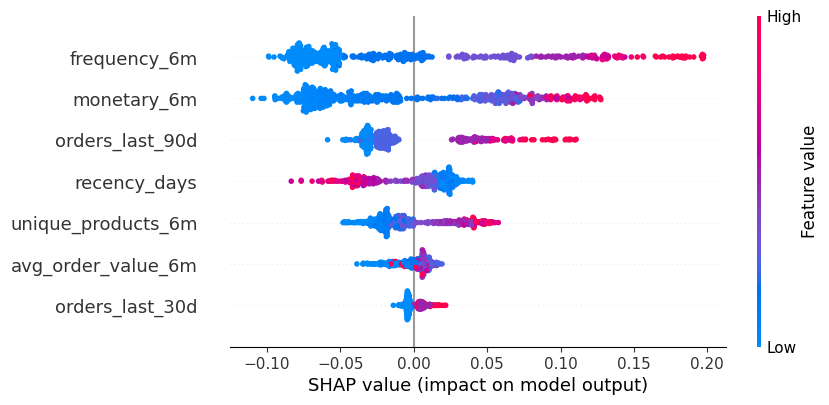

In [32]:
import shap
import matplotlib.pyplot as plt

# 抽取500条Validation样本用于解释
X_shap = X_val_tree.sample(
    n=500,
    random_state=42
)

# 创建Random Forest解释器
explainer = shap.TreeExplainer(rf_tuned)

# 计算SHAP Values
shap_values = explainer(X_shap)

# 提取复购类别(1)的解释
positive_idx = list(rf_tuned.classes_).index(1)
shap_positive = shap_values[:, :, positive_idx]

# 绘制Summary Plot
shap.plots.beeswarm(
    shap_positive,
    max_display=7,
    show=False
)

plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


High Probability
Predicted probability: 0.9784
SHAP reconstructed: 0.9784


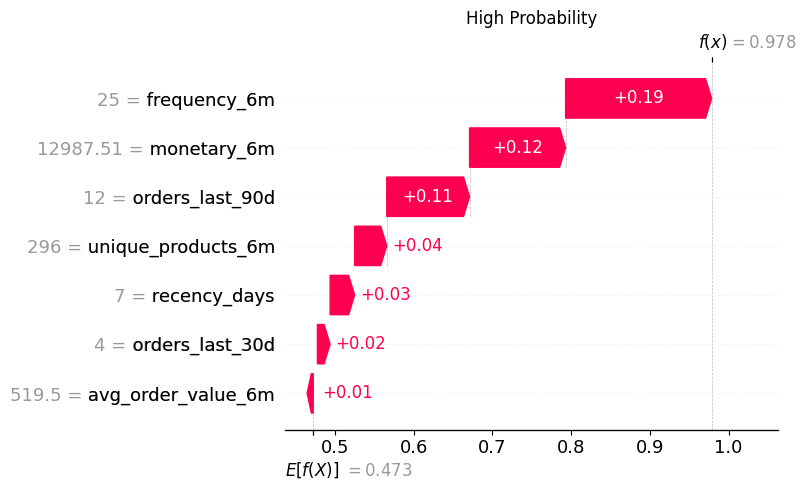


Low Probability
Predicted probability: 0.1634
SHAP reconstructed: 0.1634


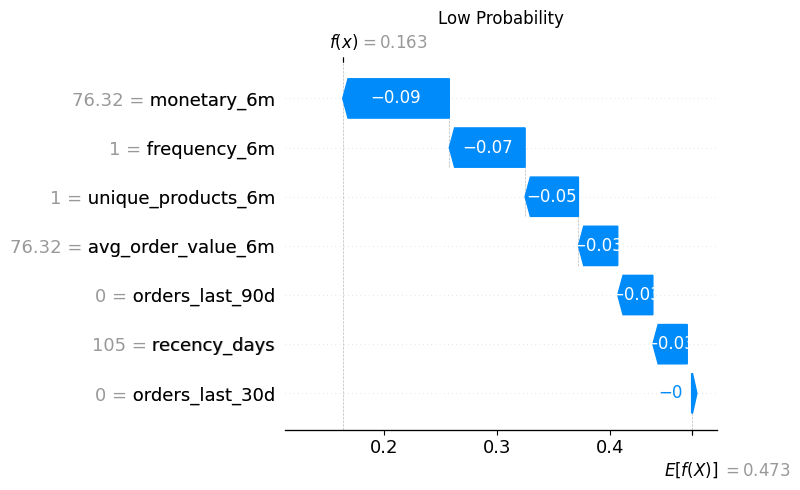

In [33]:
# 使用 Task 67 已经计算好的 SHAP Values

# 1. 获取500个客户的预测概率
probs = rf_tuned.predict_proba(X_shap)[:, 1]

# 2. 找出最高和最低预测概率的客户
high_idx = np.argmax(probs)
low_idx = np.argmin(probs)

# 3. 绘制 Waterfall Plots
for label, idx in [
    ("High Probability", high_idx),
    ("Low Probability", low_idx)
]:
    print(f"\n{label}")
    print(f"Predicted probability: {probs[idx]:.4f}")

    # 验证SHAP的加性关系
    explanation = shap_positive[idx]
    reconstructed = (
        explanation.base_values
        + explanation.values.sum()
    )

    print(f"SHAP reconstructed: {reconstructed:.4f}")

    shap.plots.waterfall(
        explanation,
        max_display=7,
        show=False
    )

    plt.title(label)
    plt.tight_layout()
    plt.savefig(
        f"shap_{label.lower().replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

Expanded LR Brier Score: 0.2006
Random Forest Brier Score: 0.1993


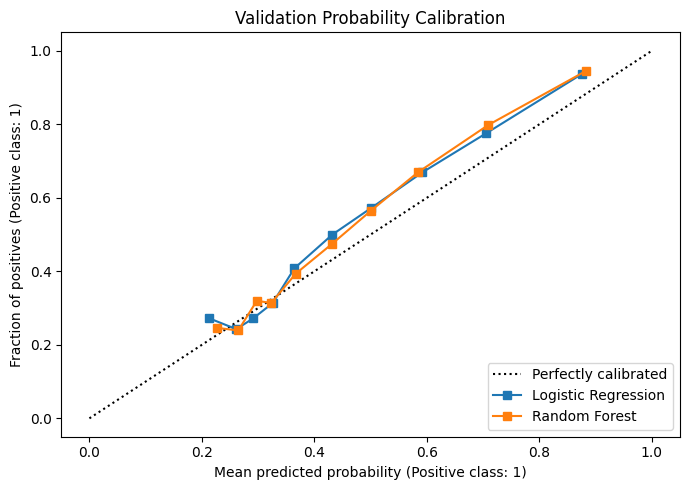

In [34]:
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

# 两个候选模型在 Validation Set 上的预测概率
lr_proba = expanded_lr.predict_proba(X_val_exp)[:, 1]
rf_proba = rf_tuned.predict_proba(X_val_tree)[:, 1]

print("Expanded LR Brier Score:",
      round(brier_score_loss(y_val, lr_proba), 4))

print("Random Forest Brier Score:",
      round(brier_score_loss(y_val, rf_proba), 4))

# Calibration Curve
fig, ax = plt.subplots(figsize=(7, 5))

CalibrationDisplay.from_predictions(
    y_val, lr_proba,
    n_bins=10,
    strategy="quantile",
    name="Logistic Regression",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_val, rf_proba,
    n_bins=10,
    strategy="quantile",
    name="Random Forest",
    ax=ax
)

ax.set_title("Validation Probability Calibration")
plt.tight_layout()
plt.show()

In [35]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

cat_model = CatBoostClassifier(
    iterations=400,
    depth=4,
    learning_rate=0.03,
    l2_leaf_reg=10,
    loss_function="Logloss",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_model.fit(X_train_tree, y_train)

cat_train_proba = cat_model.predict_proba(X_train_tree)[:, 1]
cat_val_proba = cat_model.predict_proba(X_val_tree)[:, 1]

print("CatBoost Results")
print(f"Train ROC-AUC: {roc_auc_score(y_train, cat_train_proba):.4f}")
print(f"Val ROC-AUC:   {roc_auc_score(y_val, cat_val_proba):.4f}")
print(f"Val AP:        {average_precision_score(y_val, cat_val_proba):.4f}")
print(f"Val Brier:     {brier_score_loss(y_val, cat_val_proba):.4f}")

CatBoost Results
Train ROC-AUC: 0.7472
Val ROC-AUC:   0.7572
Val AP:        0.7823
Val Brier:     0.1992


In [36]:
from sqlalchemy import text
import pandas as pd
import numpy as np

# 读取 V2 特征
v2_df = pd.read_sql(
    text("SELECT * FROM snapshot_behavioral_features_v2"),
    engine
)

# 移除仅用于 SQL 检查的字段
v2_df = v2_df.drop(columns=["recent_90_check"])

# 统一数据类型
v2_df["cutoff_date"] = pd.to_datetime(
    v2_df["cutoff_date"]
).dt.normalize()

v2_df["customer_id"] = pd.to_numeric(
    v2_df["customer_id"]
).astype("Int64")

# 定义合并函数
def merge_v2(df):
    df = df.copy()

    df["cutoff_date"] = pd.to_datetime(
        df["cutoff_date"]
    ).dt.normalize()

    df["customer_id"] = pd.to_numeric(
        df["customer_id"]
    ).astype("Int64")

    result = df.merge(
        v2_df,
        on=["customer_id", "cutoff_date"],
        how="left",
        validate="one_to_one",
        indicator=True,
        sort=False
    )

    assert result["_merge"].eq("both").all()
    assert len(result) == len(df)

    return result.drop(columns="_merge")


train_v2 = merge_v2(train_new)
val_v2 = merge_v2(val_new)

print("Train:", train_v2.shape)
print("Validation:", val_v2.shape)

Train: (12426, 16)
Validation: (2718, 16)


In [37]:
# 6 个 V2 新特征
v2_new_features = [
    "active_months_6m",
    "avg_days_between_orders",
    "std_days_between_orders",
    "has_interorder_gap",
    "orders_prev_90d",
    "order_change_90d"
]

# 13 个完整特征
features_v2 = expanded_features + v2_new_features

# 树模型直接使用原始数值
X_train_v2_tree = train_v2[features_v2].copy()
X_val_v2_tree = val_v2[features_v2].copy()

# Logistic Regression 的特征
X_train_v2_lr = X_train_v2_tree.copy()
X_val_v2_lr = X_val_v2_tree.copy()

# 在 V1 的基础上增加需要取 log 的特征
log_cols_v2 = log_features + [
    "active_months_6m",
    "avg_days_between_orders",
    "std_days_between_orders",
    "orders_prev_90d"
]

# 数据检查
assert X_train_v2_tree.notna().all().all()
assert X_val_v2_tree.notna().all().all()

assert (X_train_v2_lr[log_cols_v2] >= 0).all().all()
assert (X_val_v2_lr[log_cols_v2] >= 0).all().all()

# Log Transformation
X_train_v2_lr[log_cols_v2] = np.log1p(
    X_train_v2_lr[log_cols_v2]
)

X_val_v2_lr[log_cols_v2] = np.log1p(
    X_val_v2_lr[log_cols_v2]
)

print("V2 features:", len(features_v2))

V2 features: 13


In [38]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

experiments = {
    "Logistic Regression": (
        expanded_lr,
        X_val_exp,
        X_train_v2_lr,
        X_val_v2_lr
    ),
    "Random Forest": (
        rf_tuned,
        X_val_tree,
        X_train_v2_tree,
        X_val_v2_tree
    ),
    "LightGBM": (
        lgbm_tuned,
        X_val_tree,
        X_train_v2_tree,
        X_val_v2_tree
    ),
    "CatBoost": (
        cat_model,
        X_val_tree,
        X_train_v2_tree,
        X_val_v2_tree
    )
}

results = []
v2_models = {}

for name, (old_model, X_old_val, X_new_train, X_new_val) in experiments.items():

    # V1 已训练模型
    old_proba = old_model.predict_proba(X_old_val)[:, 1]

    # V2 模型：复制配置，重新训练
    new_model = clone(old_model)
    new_model.fit(X_new_train, y_train)

    new_proba = new_model.predict_proba(X_new_val)[:, 1]

    v2_models[name] = new_model

    old_auc = roc_auc_score(y_val, old_proba)
    new_auc = roc_auc_score(y_val, new_proba)

    results.append({
        "Model": name,
        "V1 AUC": old_auc,
        "V2 AUC": new_auc,
        "AUC Change": new_auc - old_auc,
        "V1 AP": average_precision_score(y_val, old_proba),
        "V2 AP": average_precision_score(y_val, new_proba)
    })

ablation_df = pd.DataFrame(results)

display(ablation_df.round(4))

,Model,V1 AUC,V2 AUC,AUC Change,V1 AP,V2 AP
0,Logistic Regression,0.7551,0.7538,-0.0014,0.7771,0.7835
1,Random Forest,0.7573,0.7587,0.0014,0.7815,0.7871
2,LightGBM,0.7546,0.7570,0.0024,0.7797,0.7861
3,CatBoost,0.7572,0.7588,0.0016,0.7823,0.7876


In [39]:
# 汇总三个数据集的时间信息
datasets = {
    "Train": train_v2,
    "Validation": val_v2,
    "Test": test_new
}

summary = []

for name, df in datasets.items():

    dates = pd.to_datetime(df["cutoff_date"])

    summary.append({
        "dataset": name,
        "rows": len(df),
        "customers": df["customer_id"].nunique(),
        "snapshot_dates": dates.nunique(),
        "earliest_snapshot": dates.min(),
        "latest_snapshot": dates.max(),
        "duplicate_keys": df.duplicated(
            ["customer_id", "cutoff_date"]
        ).sum()
    })

snapshot_summary = pd.DataFrame(summary)

display(snapshot_summary)

,dataset,rows,customers,snapshot_dates,earliest_snapshot,latest_snapshot,duplicate_keys
0,Train,12426,4537,4,2010-06-01,2011-03-01,0
1,Validation,2718,2718,1,2011-06-01,2011-06-01,0
2,Test,2813,2813,1,2011-09-01,2011-09-01,0


In [40]:
display(
    train_v2.groupby("cutoff_date")
    .size()
    .rename("sample_count")
)

cutoff_date
2010-06-01    2703
2010-09-01    2868
2010-12-01    3497
2011-03-01    3358
Name: sample_count, dtype: int64

In [41]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# 合并已有的 Train 和 Validation 数据
X_all = pd.concat(
    [X_train_v2_tree, X_val_v2_tree],
    ignore_index=True
)

y_all = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_val)
])

dates = pd.concat(
    [train_v2["cutoff_date"], val_v2["cutoff_date"]],
    ignore_index=True
)

# 三轮时间验证
fold_dates = pd.to_datetime([
    "2010-12-01",
    "2011-03-01",
    "2011-06-01"
])

candidate_models = {
    "Random Forest": rf_tuned,
    "CatBoost": cat_model
}

cv_results = []

for fold_date in fold_dates:

    train_mask = dates < fold_date
    val_mask = dates == fold_date

    # 检查训练标签在验证开始前已经完整可观测
    assert (
        dates[train_mask] + pd.DateOffset(months=3)
        <= fold_date
    ).all()

    for name, base_model in candidate_models.items():

        model = clone(base_model)

        model.fit(
            X_all.loc[train_mask],
            y_all[train_mask.to_numpy()]
        )

        proba = model.predict_proba(
            X_all.loc[val_mask]
        )[:, 1]

        cv_results.append({
            "Model": name,
            "Validation Date": fold_date.date(),
            "Train Samples": train_mask.sum(),
            "Validation Samples": val_mask.sum(),
            "ROC-AUC": roc_auc_score(
                y_all[val_mask.to_numpy()], proba
            ),
            "AP": average_precision_score(
                y_all[val_mask.to_numpy()], proba
            )
        })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Validation Date,Train Samples,Validation Samples,ROC-AUC,AP
0,Random Forest,2010-12-01,5571,3497,0.7526,0.6939
1,CatBoost,2010-12-01,5571,3497,0.7541,0.6953
2,Random Forest,2011-03-01,9068,3358,0.7505,0.7338
3,CatBoost,2011-03-01,9068,3358,0.7450,0.7276
4,Random Forest,2011-06-01,12426,2718,0.7587,0.7871
5,CatBoost,2011-06-01,12426,2718,0.7588,0.7876


In [42]:
from sqlalchemy import text
import numpy as np
import pandas as pd

# 1. 从订单记录独立计算未来三个月复购标签
query = """
SELECT
    s.customer_id,
    s.cutoff_date,

    CASE WHEN EXISTS (
        SELECT 1
        FROM order_summary o
        WHERE o.customer_id = s.customer_id
          AND o.order_date >= s.cutoff_date
          AND o.order_date < DATE_ADD(
              s.cutoff_date, INTERVAL 3 MONTH
          )
    )
    THEN 1 ELSE 0 END AS label_recomputed

FROM customer_snapshots_candidate s

-- 暂时不查看 Test 标签
WHERE s.cutoff_date < '2011-09-01'
"""

label_check = pd.read_sql(text(query), engine)


# 2. 整理原来的 Train / Validation 标签
def get_labels(df, y):
    result = df[["customer_id", "cutoff_date"]].copy()
    result["label_original"] = np.asarray(y)
    return result


original_labels = pd.concat([
    get_labels(train_v2, y_train),
    get_labels(val_v2, y_val)
], ignore_index=True)


# 3. 统一合并键类型
for df in [label_check, original_labels]:
    df["cutoff_date"] = pd.to_datetime(
        df["cutoff_date"]
    ).dt.normalize()

    df["customer_id"] = pd.to_numeric(
        df["customer_id"]
    ).astype("Int64")


# 4. 比较标签
audit_df = original_labels.merge(
    label_check,
    on=["customer_id", "cutoff_date"],
    how="left",
    validate="one_to_one",
    indicator=True
)

mismatches = (
    audit_df["label_original"]
    != audit_df["label_recomputed"]
)

print("Total rows:", len(audit_df))
print("Unmatched rows:",
      (audit_df["_merge"] != "both").sum())
print("Label mismatches:", mismatches.sum())

# 5. 各 Snapshot 的正样本比例
display(
    audit_df.groupby("cutoff_date")[
        ["label_original", "label_recomputed"]
    ].mean().round(4)
)

Total rows: 15144
Unmatched rows: 0
Label mismatches: 0


,label_original,label_recomputed
cutoff_date,,
2010-06-01,0.4972,0.4972
2010-09-01,0.6203,0.6203
2010-12-01,0.3786,0.3786
2011-03-01,0.4244,0.4244
2011-06-01,0.4963,0.4963


In [43]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# 1. 准备最终训练数据
X_dev = pd.concat(
    [X_train_v2_tree, X_val_v2_tree],
    ignore_index=True
)

y_dev = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_val)
])

# 2. 准备 Test Set 的 V2 特征
test_v2 = merge_v2(test_new)

X_test_v2_tree = test_v2[features_v2].copy()

assert X_test_v2_tree.notna().all().all()
assert len(X_test_v2_tree) == len(y_test) == 2813

# 3. 冻结参数，重新训练最终模型
final_rf = clone(rf_tuned)
final_rf.fit(X_dev, y_dev)

# 4. Test Set 预测
test_proba = final_rf.predict_proba(
    X_test_v2_tree
)[:, 1]

# 5. 最终评估
print("=== Final Test Results ===")
print(f"Positive Rate: {np.mean(y_test):.4f}")
print(f"ROC-AUC:       {roc_auc_score(y_test, test_proba):.4f}")
print(f"AP:            {average_precision_score(y_test, test_proba):.4f}")
print(f"Brier Score:   {brier_score_loss(y_test, test_proba):.4f}")

=== Final Test Results ===
Positive Rate: 0.6047
ROC-AUC:       0.7393
AP:            0.8276
Brier Score:   0.2154


In [44]:
# 根据最终测试集的预测概率排序
test_ranked = pd.DataFrame({
    "probability": np.asarray(test_proba),
    "actual": np.asarray(y_test).astype(int)
}).sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

base_rate = test_ranked["actual"].mean()
total_positive = test_ranked["actual"].sum()

results = []

for fraction in [0.10, 0.20, 0.30]:

    k = int(np.ceil(len(test_ranked) * fraction))

    top_k = test_ranked.head(k)

    precision_k = top_k["actual"].mean()
    recall_k = top_k["actual"].sum() / total_positive
    lift_k = precision_k / base_rate

    results.append({
        "Top %": f"{fraction:.0%}",
        "Customers": k,
        "Precision@K": precision_k,
        "Recall@K": recall_k,
        "Lift@K": lift_k
    })

lift_df = pd.DataFrame(results)

display(lift_df.round(4))

,Top %,Customers,Precision@K,Recall@K,Lift@K
0,10%,282,0.9716,0.1611,1.6068
1,20%,563,0.9183,0.3039,1.5186
2,30%,844,0.8637,0.4286,1.4284


In [45]:
from importlib.metadata import version
from pathlib import Path
import sys

packages = [
    "pandas", "numpy",
    "openpyxl", "pyarrow",
    "sqlalchemy", "pymysql",
    "scikit-learn", "lightgbm", "catboost",
    "shap", "matplotlib", "ipykernel"
]

requirements = [
    f"{pkg}=={version(pkg)}"
    for pkg in packages
]

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

assert (root / "sql").is_dir(), "Please run from the project directory."

output = root / "requirements.txt"
output.write_text("\n".join(requirements) + "\n", encoding="utf-8")

print("Python:", sys.version.split()[0])
print("Saved to:", output)
print("\n".join(requirements))

Python: 3.13.0
Saved to: e:\projects\E-commerce Customer Repurchase Prediction & Analytics\requirements.txt
pandas==2.2.3
numpy==2.1.2
openpyxl==3.1.5
pyarrow==26.0.1
sqlalchemy==2.1.8
pymysql==1.2.3
scikit-learn==1.5.2
lightgbm==4.7.0
catboost==1.2.10
shap==0.54.1
matplotlib==3.9.2
ipykernel==6.29.5


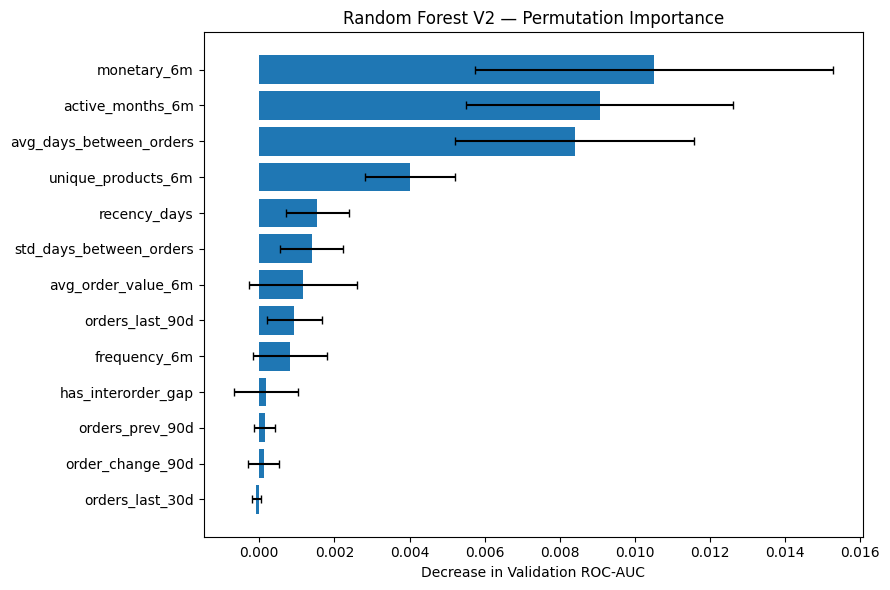

,feature,importance_mean,importance_std
2,monetary_6m,0.0105,0.0048
7,active_months_6m,0.0091,0.0036
8,avg_days_between_orders,0.0084,0.0032
6,unique_products_6m,0.0040,0.0012
0,recency_days,0.0015,0.0008
9,std_days_between_orders,0.0014,0.0008
5,avg_order_value_6m,0.0012,0.0014
4,orders_last_90d,0.0009,0.0007
1,frequency_6m,0.0008,0.0010
10,has_interorder_gap,0.0002,0.0009


In [46]:
from pathlib import Path
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# RF V2: trained on Train, evaluated on Validation
model = v2_models["Random Forest"]

perm = permutation_importance(
    model,
    X_val_v2_tree,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

importance_df = pd.DataFrame({
    "feature": features_v2,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

# Save figure
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

output_dir = root / "figures" / "rf_v2"
output_dir.mkdir(parents=True, exist_ok=True)

plot_df = importance_df.sort_values("importance_mean")

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_df["feature"],
    plot_df["importance_mean"],
    xerr=plot_df["importance_std"],
    capsize=3
)

ax.set_xlabel("Decrease in Validation ROC-AUC")
ax.set_title("Random Forest V2 — Permutation Importance")
fig.tight_layout()

fig.savefig(
    output_dir / "permutation_importance.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
display(importance_df.round(4))

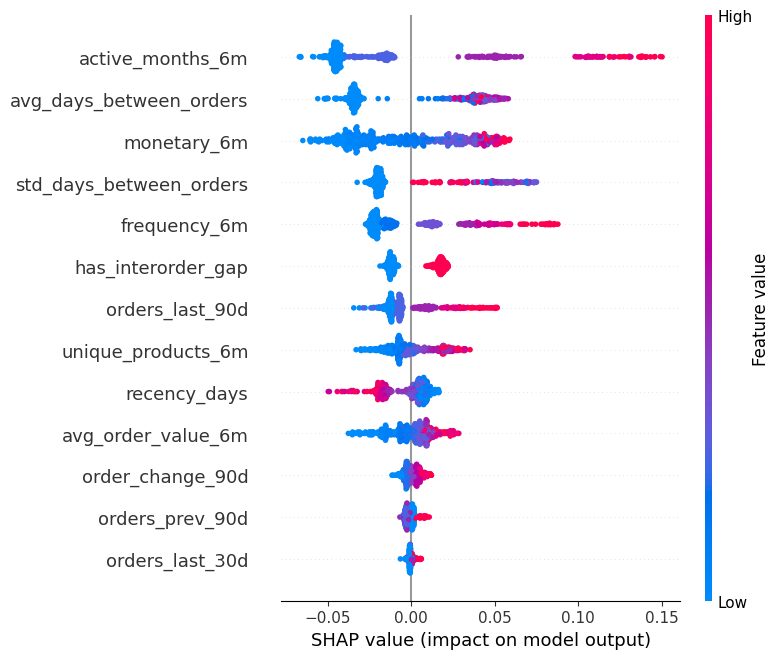

In [47]:
from pathlib import Path
import shap
import matplotlib.pyplot as plt

# Use validation-stage RF V2 model
model = v2_models["Random Forest"]

# SHAP on a manageable sample of validation data
X_shap = X_val_v2_tree.copy()
if len(X_shap) > 500:
    X_shap = X_shap.sample(n=500, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)

# For binary classification, use class 1 SHAP values if a list is returned
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    # Some SHAP versions return a 3D array or Explanation-like object behavior
    try:
        shap_values_to_plot = shap_values[:, :, 1]
    except:
        shap_values_to_plot = shap_values

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

output_dir = root / "figures" / "rf_v2"
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure()
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    show=False
)
plt.tight_layout()
plt.savefig(
    output_dir / "shap_summary.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

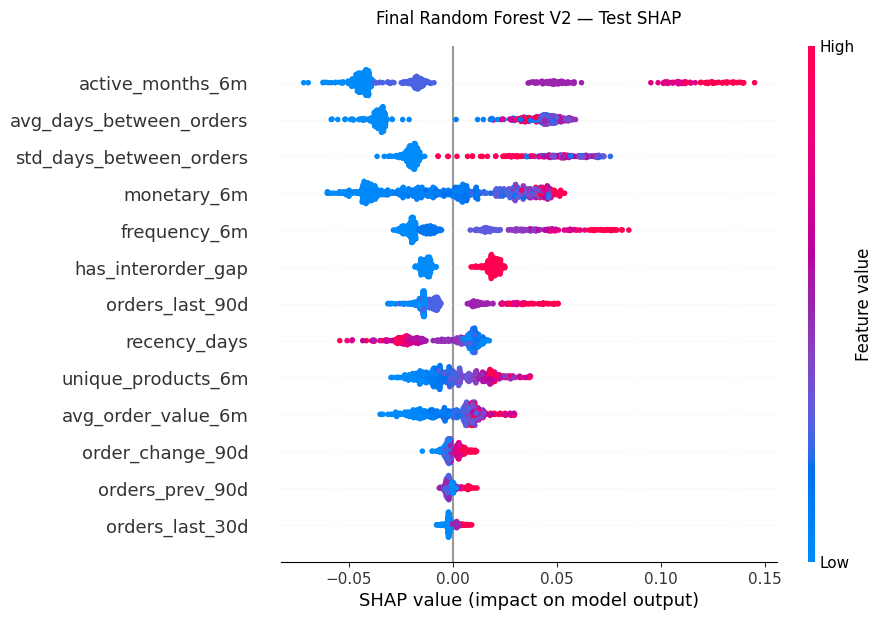

In [ ]:
import shap
import matplotlib.pyplot as plt
from pathlib import Path

# Final RF: trained on Train + Validation
X_explain = X_test_v2_tree.sample(n=500, random_state=42)

explainer = shap.TreeExplainer(final_rf)
shap_exp = explainer(X_explain)

# Binary classification: positive class
if shap_exp.values.ndim == 3:
    shap_exp = shap_exp[..., 1]

assert shap_exp.values.shape == X_explain.shape

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

output_dir = root / "figures" / "rf_v2"
output_dir.mkdir(parents=True, exist_ok=True)

shap.plots.beeswarm(
    shap_exp,
    max_display=13,
    show=False
)

plt.title("Final Random Forest V2 — Test SHAP", pad=16)
plt.savefig(
    output_dir / "shap_summary_final_rf.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

high_probability: predicted probability = 98.02%


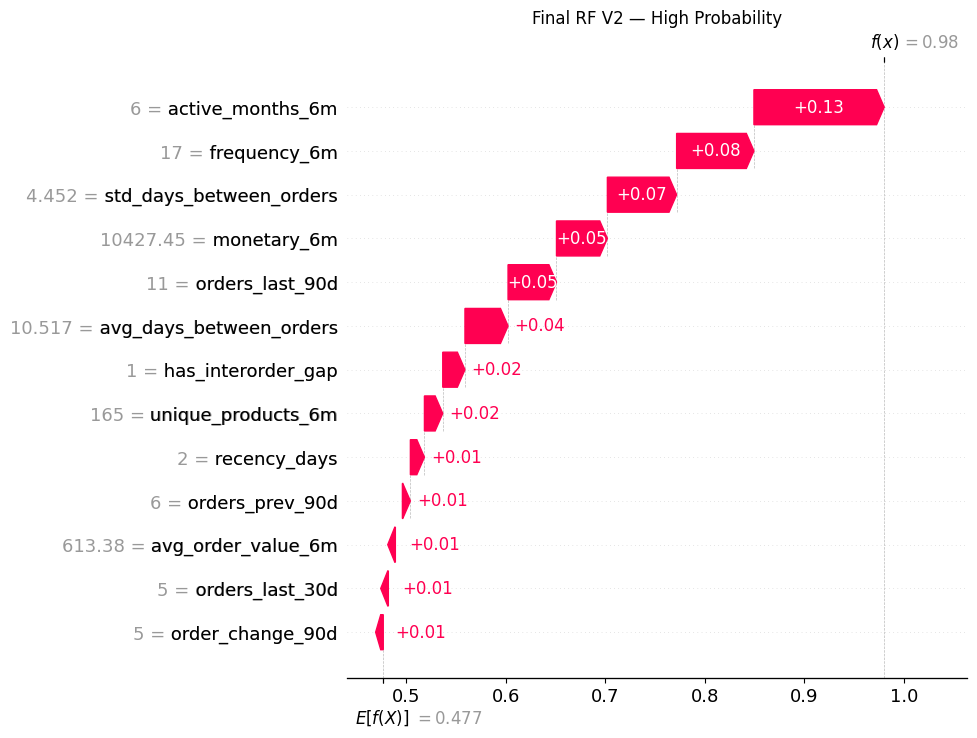

low_probability: predicted probability = 19.05%


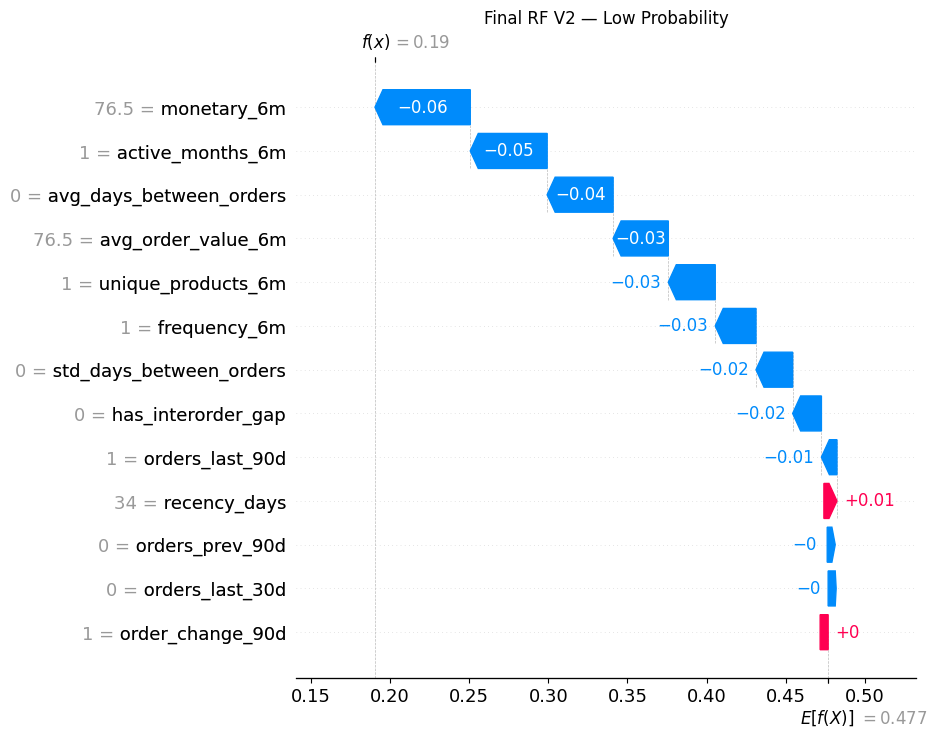

In [49]:
# Select highest- and lowest-scoring customers
# from the 500 sampled Test observations
proba = final_rf.predict_proba(X_explain)[:, 1]

examples = {
    "high_probability": proba.argmax(),
    "low_probability": proba.argmin()
}

for name, i in examples.items():
    print(f"{name}: predicted probability = {proba[i]:.2%}")

    shap.plots.waterfall(
        shap_exp[i],
        max_display=13,
        show=False
    )

    plt.title(f"Final RF V2 — {name.replace('_', ' ').title()}")
    plt.savefig(
        output_dir / f"shap_{name}_final_rf.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()